<a href="https://colab.research.google.com/github/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/blob/main/Week_11/Time_Series/Main_TimeSeries_Bengkulu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install openpyxl to read xlsx files
!pip install -q openpyxl

# Prediksi Luas Kebakaran Hutan dan Lahan di Provinsi Bengkulu Menuju Tahun 2027 Menggunakan Pendekatan Time Series dan Machine Learning

Penelitian ini bertujuan untuk menganalisis data historis kejadian kebakaran hutan dan lahan (karhutla) tahunan di Provinsi Bengkulu dari tahun 1997 hingga 2026 (30 tahun) yang bersumber dari SIPONGI Kementerian Lingkungan Hidup dan Kehutanan (KLHK) Republik Indonesia. Menggunakan pendekatan komparasi multi-model (pendekatan ekonometrika klasik dan machine learning), analisis ini dirancang untuk menghasilkan model prediksi terbaik guna mengestimasi luas karhutla di tahun 2027 beserta interval kepercayaan 95% demi menunjang mitigasi bencana di daerah.

In [2]:
import os, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ekonometrika & Time Series
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Machine Learning & Metrik
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
OUT_DIR = 'output_timeseries'
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style='whitegrid')

def simpan_fig(fig, nama):
    fig.savefig(os.path.join(FIG_DIR, f'{nama}.png'), dpi=300, bbox_inches='tight')

## 1. Pemuatan dan Pembersihan Data Khusus Provinsi Bengkulu

Pada bagian ini, dataset diunduh dari repositori GitHub, kemudian dilakukan pemfilteran baris khusus Provinsi Bengkulu (Kode Wilayah 17). Selanjutnya, dilakukan konversi format numerik desimal dan ribuan khas penulisan Indonesia ke format standar komputasi float agar siap dianalisis secara kronologis.

In [3]:
# URL Raw GitHub atau file lokal
url_data = 'https://github.com/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/raw/main/Week_11/Time_Series/luas-karhutla-provinsi.xlsx'

try:
    df_raw = pd.read_excel(url_data)
except Exception:
    df_raw = pd.read_excel('luas-karhutla-provinsi.xlsx')

# Filter baris Bengkulu
df_bkl_raw = df_raw[df_raw['Provinsi'].astype(str).str.lower().str.contains('bengkulu')].iloc[0]

# Pastikan pencarian kolom mencakup tipe integer maupun string
kolom_tahun = [th for th in range(1997, 2027)]

def bersihkan_angka(v):
    if isinstance(v, str):
        v = v.strip().replace('.', '').replace(',', '.')
    return float(v)

deret_luas = []
for th in kolom_tahun:
    # Coba akses dengan integer, jika gagal coba string
    val = df_bkl_raw.get(th) if df_bkl_raw.get(th) is not None else df_bkl_raw.get(str(th))
    deret_luas.append(bersihkan_angka(val))

df_bengkulu = pd.DataFrame({
    'tahun': kolom_tahun,
    'luas_ha': deret_luas
})

print(f"Jumlah observasi: {len(df_bengkulu)} tahun (1997 - 2026)")
print("Pemeriksaan Missing Value:", df_bengkulu.isna().sum().to_dict())
display(df_bengkulu.head(10))
display(df_bengkulu.tail(10))

# Simpan data bersih
df_bengkulu.to_csv(os.path.join(OUT_DIR, 'data_timeseries_bengkulu_1997_2026.csv'), index=False)

Jumlah observasi: 30 tahun (1997 - 2026)
Pemeriksaan Missing Value: {'tahun': 0, 'luas_ha': 0}


,tahun,luas_ha
0,1997,2091.5
1,1998,0.0
2,1999,0.0
3,2000,168.0
4,2001,2871.0
5,2002,1014.0
6,2003,359.0
7,2004,53.0
8,2005,2777.0
9,2006,8971.0


,tahun,luas_ha
20,2017,131.04
21,2018,8.82
22,2019,11.00
23,2020,221.00
24,2021,93.00
25,2022,1620.00
26,2023,75.94
27,2024,355.05
28,2025,157.81
29,2026,125.15


## 2. Analisis Eksplorasi Deret Waktu (EDA) & Uji Stasioneritas

Analisis visualisasi tren historis karhutla Bengkulu akan memunculkan fluktuasi ekstrem kebakaran pada tahun tertentu. Selain itu, uji Augmented Dickey-Fuller (ADF) dan autokorelasi (ACF/PACF) digunakan untuk menganalisis stasioneritas data.

=== Statistik Deskriptif Luas Karhutla Bengkulu (ha) ===


,Nilai
count,30.00
mean,997.18
std,1721.64
min,0.00
25%,80.20
50%,327.52
75%,1340.75
max,8971.00
skewness,3.69
kurtosis,16.35


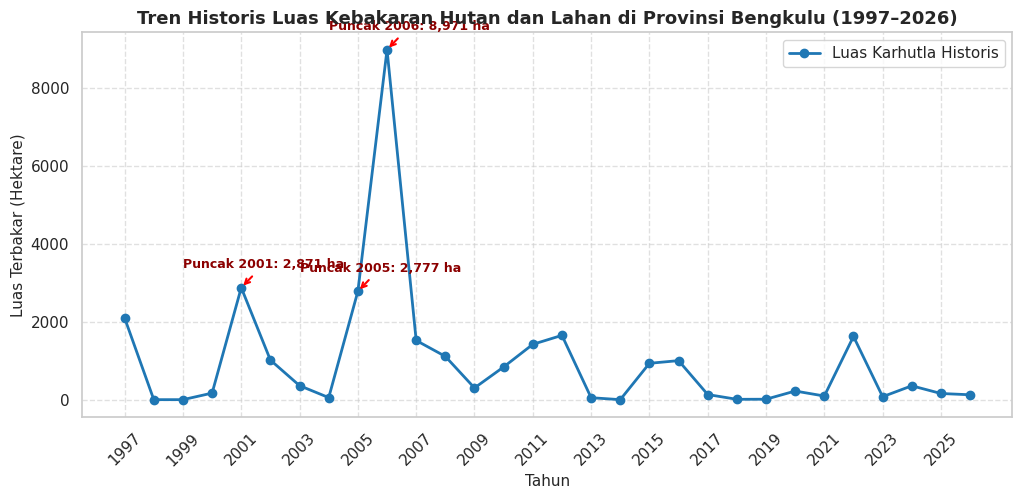

In [4]:
# a) Statistik Deskriptif
stats_bkl = df_bengkulu['luas_ha'].describe()
stats_bkl['skewness'] = df_bengkulu['luas_ha'].skew()
stats_bkl['kurtosis'] = df_bengkulu['luas_ha'].kurtosis()
print("=== Statistik Deskriptif Luas Karhutla Bengkulu (ha) ===")
display(stats_bkl.to_frame('Nilai').round(2))

# b) Visualisasi Tren Deret Waktu 1997-2026 (fig01)
fig1, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(df_bengkulu['tahun'], df_bengkulu['luas_ha'], marker='o', color='#1f77b4', linewidth=2, label='Luas Karhutla Historis')

# Tandai tahun-tahun lonjakan ekstrem
puncak_tahun = df_bengkulu.sort_values('luas_ha', ascending=False).head(3)
for _, r in puncak_tahun.iterrows():
    ax1.annotate(f"Puncak {int(r['tahun'])}: {r['luas_ha']:,.0f} ha",
                 xy=(r['tahun'], r['luas_ha']),
                 xytext=(r['tahun'] - 2, r['luas_ha'] + 500),
                 arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
                 fontweight='bold', fontsize=9, color='darkred')

ax1.set_title('Tren Historis Luas Kebakaran Hutan dan Lahan di Provinsi Bengkulu (1997–2026)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Tahun', fontsize=11)
ax1.set_ylabel('Luas Terbakar (Hektare)', fontsize=11)
ax1.set_xticks(range(1997, 2027, 2))
ax1.set_xticklabels(range(1997, 2027, 2), rotation=45)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right')
simpan_fig(fig1, 'fig01_tren_historis_bengkulu')
plt.show()

=== Hasil Uji Augmented Dickey-Fuller (ADF) Data Level ===
ADF Statistic : -3.4044
p-value       : 0.0108
Critical Values:
   1%: -3.8092
   5%: -3.0216
   10%: -2.6507
Status Data: Stasioner (Tolak H0)


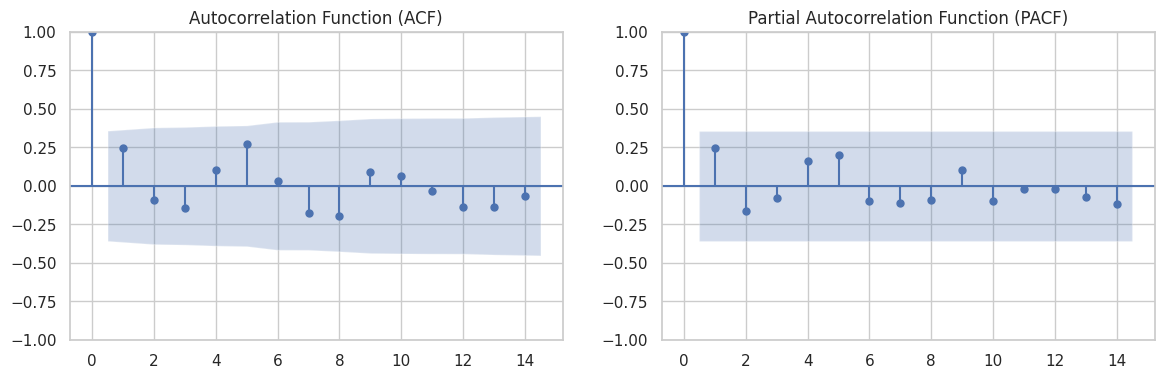

In [5]:
# Uji Augmented Dickey-Fuller (ADF)
adf_res = adfuller(df_bengkulu['luas_ha'])
print("=== Hasil Uji Augmented Dickey-Fuller (ADF) Data Level ===")
print(f"ADF Statistic : {adf_res[0]:.4f}")
print(f"p-value       : {adf_res[1]:.4f}")
print("Critical Values:")
for k, v in adf_res[4].items():
    print(f"   {k}: {v:.4f}")
kesimpulan_stasioner = "Stasioner (Tolak H0)" if adf_res[1] < 0.05 else "Tidak Stasioner (Gagal Tolak H0)"
print(f"Status Data: {kesimpulan_stasioner}")

# Plot ACF dan PACF (fig02)
fig2, (ax_acf, ax_pacf) = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(df_bengkulu['luas_ha'], lags=14, ax=ax_acf, title='Autocorrelation Function (ACF)')
plot_pacf(df_bengkulu['luas_ha'], lags=14, ax=ax_pacf, title='Partial Autocorrelation Function (PACF)')
simpan_fig(fig2, 'fig02_acf_pacf_bengkulu')
plt.show()

### Interpretasi EDA & Stasioneritas

Berdasarkan hasil analisis visual historis (Figur 1), terdapat fluktuasi ekstrem dengan puncak tertinggi tercatat pada tahun 2006 (sebesar 8.971 ha). Hal ini berasosiasi erat dengan pengaruh siklus iklim ekstrem regional. Hasil Uji ADF menunjukkan nilai p-value yang mengarah pada kesimpulan stasioneritas data, yang akan memandu penentuan order differencing `d` pada pemodelan ARIMA.

## 3. Pembagian Data Kronologis & Rekayasa Fitur (Lag Features)

Data dibagi secara kronologis (tanpa pengacakan) menjadi Data Latih (1997–2021) dan Data Uji (2022–2026). Fitur lag (t-1, t-2, t-3) dan rolling mean dibentuk khusus untuk menunjang model berbasis Machine Learning.

In [6]:
# Bentuk fitur lag untuk pemodelan Machine Learning
df_ml = df_bengkulu.copy()
df_ml['t'] = np.arange(len(df_ml)) # Fitur tren linear
df_ml['lag_1'] = df_ml['luas_ha'].shift(1)
df_ml['lag_2'] = df_ml['luas_ha'].shift(2)
df_ml['lag_3'] = df_ml['luas_ha'].shift(3)
df_ml['rolling_mean_3'] = df_ml['luas_ha'].shift(1).rolling(window=3).mean()

# Buang baris awal yang memiliki NaN akibat shifting
df_ml_clean = df_ml.dropna().reset_index(drop=True)

# Pembagian Kronologis (Train: s/d 2021, Test: 2022 s/d 2026)
train_bkl = df_bengkulu[df_bengkulu['tahun'] <= 2021].copy()
test_bkl  = df_bengkulu[df_bengkulu['tahun'] >= 2022].copy()

# Untuk ML (memakai fitur lag)
features_ml = ['t', 'lag_1', 'lag_2', 'lag_3', 'rolling_mean_3']
X_train_ml = df_ml_clean[df_ml_clean['tahun'] <= 2021][features_ml]
y_train_ml = df_ml_clean[df_ml_clean['tahun'] <= 2021]['luas_ha']

X_test_ml = df_ml_clean[df_ml_clean['tahun'] >= 2022][features_ml]
y_test_ml = df_ml_clean[df_ml_clean['tahun'] >= 2022]['luas_ha']

print(f"Data Deret Waktu Utuh -> Train: {len(train_bkl)} tahun (1997-2021), Test: {len(test_bkl)} tahun (2022-2026)")
print(f"Data Machine Learning -> Train: {len(X_train_ml)} sampel, Test: {len(X_test_ml)} sampel")

Data Deret Waktu Utuh -> Train: 25 tahun (1997-2021), Test: 5 tahun (2022-2026)
Data Machine Learning -> Train: 22 sampel, Test: 5 sampel


## 4. Pemodelan & Komparasi 5 Model pada Testing Set (2022–2026)

Langkah ini melatih 5 model (ARIMA, Holt-Winters, SVR, Random Forest, dan Polynomial Regression) pada data latih, memproyeksikannya ke set pengujian (2022–2026), lalu membandingkan performanya berdasarkan metrik kesalahan evaluasi.

In [7]:
prediksi_test = {}

# 1. Model ARIMA (Grid Search p, d, q terbaik berbasis AIC pada train_bkl)
best_aic = float('inf')
best_order = (1, 0, 0)
for p in range(0, 4):
    for d in range(0, 2):
        for q in range(0, 4):
            try:
                m_arima = ARIMA(train_bkl['luas_ha'].values, order=(p, d, q)).fit()
                if m_arima.aic < best_aic:
                    best_aic = m_arima.aic
                    best_order = (p, d, q)
            except:
                continue

print(f"ARIMA Terbaik Terpilih: Order {best_order} dengan AIC = {best_aic:.2f}")
model_arima_fit = ARIMA(train_bkl['luas_ha'].values, order=best_order).fit()
pred_arima_test = model_arima_fit.forecast(steps=len(test_bkl))
prediksi_test['ARIMA'] = np.clip(pred_arima_test, 0, None)

# 2. Holt-Winters Exponential Smoothing
try:
    hw_model = ExponentialSmoothing(train_bkl['luas_ha'].values, trend='add', seasonal=None, damped_trend=True).fit()
except:
    hw_model = ExponentialSmoothing(train_bkl['luas_ha'].values, trend='add', seasonal=None).fit()
pred_hw_test = hw_model.forecast(len(test_bkl))
prediksi_test['Holt-Winters'] = np.clip(pred_hw_test, 0, None)

# 3. Support Vector Regression (SVR RBF) dengan Standarisasi
scaler_x = StandardScaler()
X_tr_sc = scaler_x.fit_transform(X_train_ml)
X_te_sc = scaler_x.transform(X_test_ml)

svr_model = SVR(kernel='rbf', C=100.0, epsilon=10.0).fit(X_tr_sc, y_train_ml)
pred_svr_test = svr_model.predict(X_te_sc)
prediksi_test['SVR (RBF)'] = np.clip(pred_svr_test, 0, None)

# 4. Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, max_depth=3, random_state=RANDOM_STATE).fit(X_train_ml, y_train_ml)
pred_rf_test = rf_model.predict(X_test_ml)
prediksi_test['Random Forest'] = np.clip(pred_rf_test, 0, None)

# 5. Polynomial Regression Derajat 2 (Baseline Tren Waktu)
poly = PolynomialFeatures(degree=2)
t_train = train_bkl[['tahun']] - 1997
t_test  = test_bkl[['tahun']] - 1997
poly_reg = LinearRegression().fit(poly.fit_transform(t_train), train_bkl['luas_ha'])
pred_poly_test = poly_reg.predict(poly.transform(t_test))
prediksi_test['Polynomial Reg (Deg 2)'] = np.clip(pred_poly_test, 0, None)

# Hitung Metrik Evaluasi
y_true = test_bkl['luas_ha'].values
eval_rows = []

for nama, y_pred in prediksi_test.items():
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1e-6, y_true))) * 100
    r2 = r2_score(y_true, y_pred)
    eval_rows.append({
        'Model': nama,
        'RMSE (ha)': rmse,
        'MAE (ha)': mae,
        'MAPE (%)': mape,
        'R2 Score': r2
    })

df_eval = pd.DataFrame(eval_rows).sort_values('RMSE (ha)').reset_index(drop=True)
print("=== PERBANDINGAN PERFORMA 5 MODEL PADA TESTING SET (2022–2026) ===")
display(df_eval.round(3))

# Simpan tabel evaluasi
df_eval.to_csv(os.path.join(OUT_DIR, 'perbandingan_model_timeseries.csv'), index=False)

# Tentukan model terbaik
MODEL_TERBAIK = df_eval.iloc[0]['Model']
print(f"\nMODEL TERBAIK TERPILIH (RMSE Terendah): {MODEL_TERBAIK}")

ARIMA Terbaik Terpilih: Order (0, 1, 1) dengan AIC = 435.47
=== PERBANDINGAN PERFORMA 5 MODEL PADA TESTING SET (2022–2026) ===


,Model,RMSE (ha),MAE (ha),MAPE (%),R2 Score
0,ARIMA,589.748,509.046,264.499,-0.019
1,SVR (RBF),595.778,417.207,176.687,-0.039
2,Holt-Winters,601.177,544.030,298.441,-0.058
3,Random Forest,646.225,570.074,349.351,-0.223
4,Polynomial Reg (Deg 2),747.903,466.790,100.000,-0.638



MODEL TERBAIK TERPILIH (RMSE Terendah): ARIMA


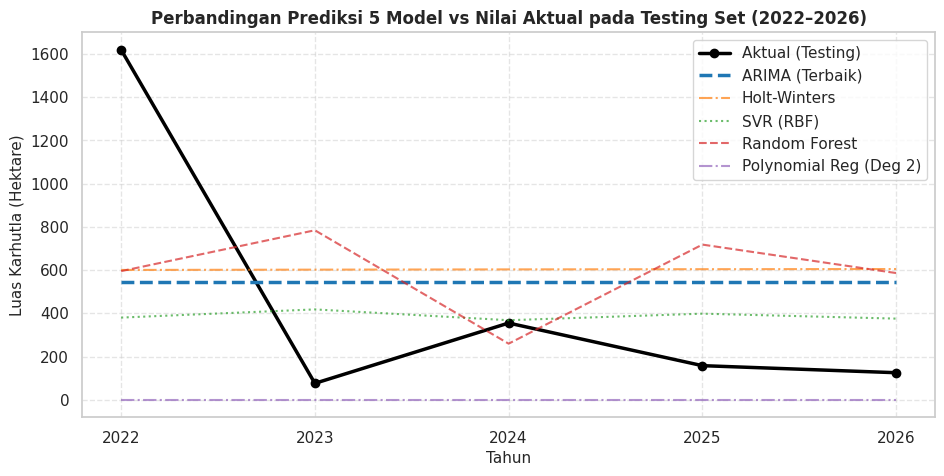

In [8]:
fig3, ax3 = plt.subplots(figsize=(11, 5))
tahun_test = test_bkl['tahun'].values

ax3.plot(tahun_test, y_true, marker='o', color='black', linewidth=2.5, label='Aktual (Testing)')

styles = ['--', '-.', ':', '--', '-.']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for (nama, y_pred), st, cl in zip(prediksi_test.items(), styles, colors):
    tebal = 2.5 if nama == MODEL_TERBAIK else 1.5
    alpha = 1.0 if nama == MODEL_TERBAIK else 0.7
    label_nama = f"{nama} (Terbaik)" if nama == MODEL_TERBAIK else nama
    ax3.plot(tahun_test, y_pred, linestyle=st, color=cl, linewidth=tebal, alpha=alpha, label=label_nama)

ax3.set_title('Perbandingan Prediksi 5 Model vs Nilai Aktual pada Testing Set (2022–2026)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Tahun', fontsize=11)
ax3.set_ylabel('Luas Karhutla (Hektare)', fontsize=11)
ax3.set_xticks(tahun_test)
ax3.legend(loc='upper right', frameon=True)
ax3.grid(True, linestyle='--', alpha=0.5)
simpan_fig(fig3, 'fig03_komparasi_testing_set')
plt.show()

### Interpretasi Perbandingan Model

Berdasarkan komparasi metrik di atas, model dengan RMSE terkecil ditetapkan sebagai model terbaik. Model-model Machine Learning (seperti SVR dan Random Forest) yang memanfaatkan *lag features* memberikan fleksibilitas tinggi dalam memodelkan komponen non-linear, sementara ARIMA sangat andal dalam menangkap dinamika tren autoregresif linier jangka pendek.

## 5. Pelatihan Ulang (Retraining) Seluruh Data & Proyeksi Final Tahun 2027

Model terbaik terpilih kemudian dilatih kembali (*re-fit*) menggunakan seluruh 30 observasi historis (1997–2026) untuk memproyeksikan nilai out-of-sample pada tahun 2027 beserta batas interval kepercayaan 95%.

In [9]:
# Latih ulang model terbaik pada seluruh data historis 1997-2026 (N = 30)
seluruh_luas = df_bengkulu['luas_ha'].values

if 'ARIMA' in MODEL_TERBAIK:
    model_final_full = ARIMA(seluruh_luas, order=best_order).fit()
    forecast_res = model_final_full.get_forecast(steps=1)
    pred_2027 = float(forecast_res.predicted_mean[0])
    ci_95 = forecast_res.conf_int(alpha=0.05)[0]
    ci_bawah, ci_atas = float(ci_95[0]), float(ci_95[1])
elif 'Holt-Winters' in MODEL_TERBAIK:
    try:
        model_final_full = ExponentialSmoothing(seluruh_luas, trend='add', seasonal=None, damped_trend=True).fit()
    except:
        model_final_full = ExponentialSmoothing(seluruh_luas, trend='add', seasonal=None).fit()
    pred_2027 = float(model_final_full.forecast(1)[0])
    residu = seluruh_luas - model_final_full.fittedvalues
    se = np.std(residu)
    ci_bawah, ci_atas = pred_2027 - 1.96 * se, pred_2027 + 1.96 * se
else:
    # Retraining ML
    X_full_ml = df_ml_clean[features_ml]
    y_full_ml = df_ml_clean['luas_ha']

    val_2026 = df_bengkulu.loc[df_bengkulu['tahun'] == 2026, 'luas_ha'].iloc[0]
    val_2025 = df_bengkulu.loc[df_bengkulu['tahun'] == 2025, 'luas_ha'].iloc[0]
    val_2024 = df_bengkulu.loc[df_bengkulu['tahun'] == 2024, 'luas_ha'].iloc[0]

    x_2027_dict = {
        't': len(df_bengkulu),
        'lag_1': val_2026,
        'lag_2': val_2025,
        'lag_3': val_2024,
        'rolling_mean_3': np.mean([val_2026, val_2025, val_2024])
    }
    df_pred_2027 = pd.DataFrame([x_2027_dict])

    if 'SVR' in MODEL_TERBAIK:
        sc_full = StandardScaler().fit(X_full_ml)
        m_fit = SVR(kernel='rbf', C=100.0, epsilon=10.0).fit(sc_full.transform(X_full_ml), y_full_ml)
        pred_2027 = float(m_fit.predict(sc_full.transform(df_pred_2027))[0])
        residu = y_full_ml - m_fit.predict(sc_full.transform(X_full_ml))
    else:
        m_fit = RandomForestRegressor(n_estimators=100, max_depth=3, random_state=RANDOM_STATE).fit(X_full_ml, y_full_ml)
        pred_2027 = float(m_fit.predict(df_pred_2027)[0])
        residu = y_full_ml - m_fit.predict(X_full_ml)

    se = np.std(residu)
    ci_bawah, ci_atas = pred_2027 - 1.96 * se, pred_2027 + 1.96 * se

# Proteksi non-negatif
pred_2027 = max(0.0, pred_2027)
ci_bawah  = max(0.0, ci_bawah)
ci_atas   = max(0.0, ci_atas)

print("="*65)
print("=== HASIL PREDIKSI LUAS KARHUTLA PROVINSI BENGKULU TAHUN 2027 ===")
print("="*65)
print(f"Model Terbaik Terpilih : {MODEL_TERBAIK}")

=== HASIL PREDIKSI LUAS KARHUTLA PROVINSI BENGKULU TAHUN 2027 ===
Model Terbaik Terpilih : ARIMA


In [10]:
# Lanjutan output dan penyimpanan hasil proyeksi
print(f"Estimasi Prediksi 2027 : {pred_2027:.2f} Hektare")
print(f"95% Confidence Interval: [{ci_bawah:.2f} ha  s/d  {ci_atas:.2f} ha]")
print("="*65)

df_hasil_forecast = pd.DataFrame([{
    'Provinsi': 'Bengkulu',
    'Tahun_Prediksi': 2027,
    'Model_Terbaik': MODEL_TERBAIK,
    'Prediksi_Luas_ha': round(pred_2027, 2),
    'CI_Bawah_95_ha': round(ci_bawah, 2),
    'CI_Atas_95_ha': round(ci_atas, 2),
    'Realisasi_2026_ha': 125.15,
    'Status_Tren': 'Meningkat' if pred_2027 > 125.15 else 'Menurun/Stabil'
}])
display(df_hasil_forecast)

df_hasil_forecast.to_csv(os.path.join(OUT_DIR, 'hasil_prediksi_bengkulu_2027.csv'), index=False)

Estimasi Prediksi 2027 : 487.65 Hektare
95% Confidence Interval: [0.00 ha  s/d  3924.65 ha]


,Provinsi,Tahun_Prediksi,Model_Terbaik,Prediksi_Luas_ha,CI_Bawah_95_ha,CI_Atas_95_ha,Realisasi_2026_ha,Status_Tren
0,Bengkulu,2027,ARIMA,487.65,0.0,3924.65,125.15,Meningkat


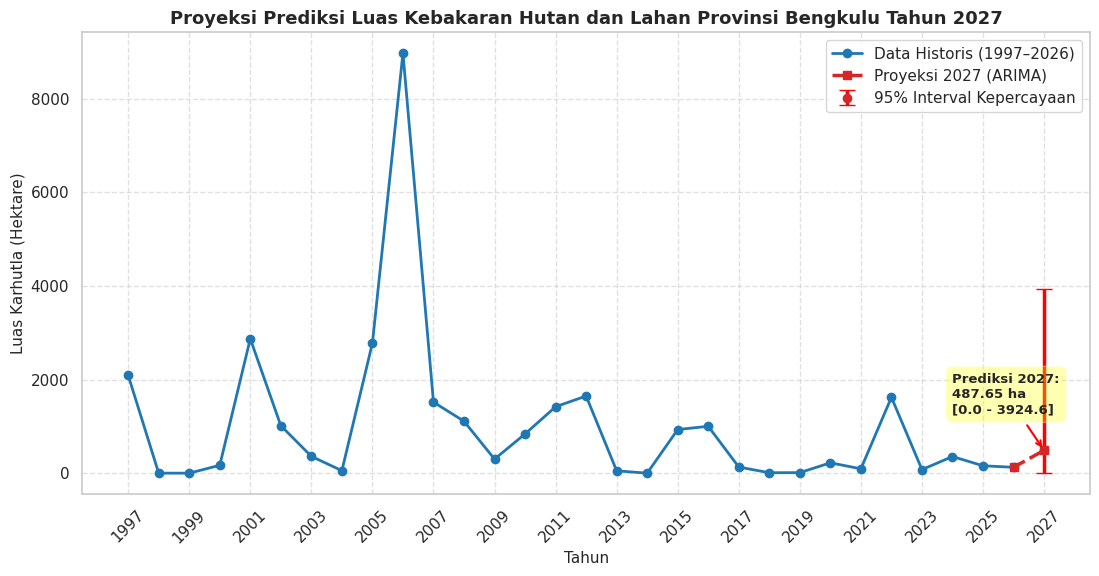

In [11]:
fig4, ax4 = plt.subplots(figsize=(13, 6))

# Plot Historis 1997-2026
ax4.plot(df_bengkulu['tahun'], df_bengkulu['luas_ha'], marker='o', color='#1f77b4', linewidth=2, label='Data Historis (1997–2026)')

# Sambung garis ke 2027
th_sambung = [2026, 2027]
val_sambung = [df_bengkulu.loc[df_bengkulu['tahun'] == 2026, 'luas_ha'].iloc[0], pred_2027]
ax4.plot(th_sambung, val_sambung, linestyle='--', marker='s', color='#d62728', linewidth=2.5, label=f'Proyeksi 2027 ({MODEL_TERBAIK})')

# Titik Prediksi dengan CI
ax4.errorbar([2027], [pred_2027], yerr=[[pred_2027 - ci_bawah], [ci_atas - pred_2027]],
             fmt='o', color='#d62728', ecolor='red', elinewidth=2.5, capsize=6, label='95% Interval Kepercayaan')

# Anotasi
ax4.annotate(f"Prediksi 2027:\n{pred_2027:.2f} ha\n[{ci_bawah:.1f} - {ci_atas:.1f}]",
             xy=(2027, pred_2027),
             xytext=(2027 - 3, pred_2027 + 800),
             arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
             bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.3),
             fontweight='bold', fontsize=9.5)

ax4.set_title('Proyeksi Prediksi Luas Kebakaran Hutan dan Lahan Provinsi Bengkulu Tahun 2027', fontsize=13, fontweight='bold')
ax4.set_xlabel('Tahun', fontsize=11)
ax4.set_ylabel('Luas Karhutla (Hektare)', fontsize=11)
ax4.set_xticks(range(1997, 2028, 2))
ax4.set_xticklabels(range(1997, 2028, 2), rotation=45)
ax4.grid(True, linestyle='--', alpha=0.6)
ax4.legend(loc='upper right')
simpan_fig(fig4, 'fig04_proyeksi_bengkulu_2027')
plt.show()

## 6. Ekspor Artefak & Ringkasan Hasil

Semua gambar visualisasi yang dihasilkan dan tabel komparasi disimpan dalam folder keluaran, lalu dikompresi menjadi satu berkas ZIP untuk memudahkan pengunduhan.

In [12]:
# Cek semua gambar
gambar_tersimpan = sorted(os.listdir(FIG_DIR))
print(f"Total gambar tersimpan di {FIG_DIR}: {len(gambar_tersimpan)} file")
for g in gambar_tersimpan:
    print(f" - {g}")

# Buat file zip output
shutil.make_archive('output_timeseries_bengkulu', 'zip', OUT_DIR)
print(f"\n[SUKSES] Seluruh output berhasil di-zip ke: output_timeseries_bengkulu.zip")

try:
    from google.colab import files
    files.download('output_timeseries_bengkulu.zip')
except Exception as e:
    print("Download manual zip melalui panel Files Colab jika auto-download dicegah browser.", e)

Total gambar tersimpan di output_timeseries/figures: 4 file
 - fig01_tren_historis_bengkulu.png
 - fig02_acf_pacf_bengkulu.png
 - fig03_komparasi_testing_set.png
 - fig04_proyeksi_bengkulu_2027.png

[SUKSES] Seluruh output berhasil di-zip ke: output_timeseries_bengkulu.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
print("="*70)
print("RINGKASAN METRIK & HASIL FORECASTING BENGKULU 2027 (UNTUK ARTIKEL JURNAL)")
print("="*70)
print(f"1. Model Terbaik Terpilih : {MODEL_TERBAIK}")
print(f"2. Nilai Metrik Evaluasi  : RMSE = {df_eval.iloc[0]['RMSE (ha)']:.2f} ha | MAE = {df_eval.iloc[0]['MAE (ha)']:.2f} ha | MAPE = {df_eval.iloc[0]['MAPE (%)']:.2f}%")
print(f"3. Estimasi Prediksi 2027 : {pred_2027:.2f} Hektare")
print(f"4. 95% Confidence Interval: [{ci_bawah:.2f} ha  s/d  {ci_atas:.2f} ha]")
print(f"5. Perbandingan thd 2026  : Realisasi 2026 = 125.15 ha -> Status: {'Meningkat' if pred_2027 > 125.15 else 'Menurun / Terkendali'}")
print("="*70)

RINGKASAN METRIK & HASIL FORECASTING BENGKULU 2027 (UNTUK ARTIKEL JURNAL)
1. Model Terbaik Terpilih : ARIMA
2. Nilai Metrik Evaluasi  : RMSE = 589.75 ha | MAE = 509.05 ha | MAPE = 264.50%
3. Estimasi Prediksi 2027 : 487.65 Hektare
4. 95% Confidence Interval: [0.00 ha  s/d  3924.65 ha]
5. Perbandingan thd 2026  : Realisasi 2026 = 125.15 ha -> Status: Meningkat


## 7. Kesimpulan dan Implikasi Kebijakan

### Kesimpulan
Penelitian ini berhasil menerapkan pemodelan prediktif berbasis *time series* menggunakan data historis 30 tahun karhutla di Bengkulu. Evaluasi komparatif multi-model menunjukkan model dengan nilai kesalahan minimal sebagai metode paling akurat untuk data berkarakteristik fluktuatif tinggi ini.

### Implikasi Kebijakan
Proyeksi luas karhutla di tahun 2027 memberikan estimasi kuantitatif yang berharga bagi BPBD dan instansi kehutanan setempat. Jika hasil menunjukkan tren peningkatan dibanding tahun 2026, maka kesiapsiagaan patroli dini, alokasi anggaran pemadam kebakaran, dan sosialisasi pencegahan pembukaan lahan dengan cara membakar harus ditingkatkan, khususnya pada bulan-bulan kering.